# `explain_residues.py`, step by step

**Question:** when the LoRA classifier calls an enzyme *active*, which residues drive that decision? Are they the catalytic residues?

The notebook takes **one sequence** through the script's pipeline. It opens up each function and checks every claim in the docstring numerically:

| # | step | script function |
|---|---|---|
| 1 | load the model from a run dir | `load_model` |
| 2 | pick a sequence with known catalytic sites | `main` (data part) |
| 3 | tokenize: `<cls>` and `<eos>`, and how token index maps to residue position | `main` |
| 4 | forward pass: hidden states → mean pool → head → logit | `EsmLoraClassifier` |
| 5 | **why plain Grad-CAM is flat** (the gradient is the same at every residue) | docstring |
| 6 | gradient × activation is an **exact** split of `g · pooled` | `attribution_gradcam` |
| 7 | all 34 layers → a layer × position map | `attribution_gradcam(all_layers=True)` |
| 8 | integrated gradients | `attribution_intgrad` |
| 9 | percentile ranks and enrichment at catalytic sites | `main` (summary part) |
| 10 | the same summary on all 200 precomputed sequences (no GPU needed) | `summary.json` |

Steps 1–9 need `torch`, `transformers` and `peft`. A GPU is best, but a CPU works for one sequence of a few hundred residues. Step 10 needs only `pandas` and `matplotlib`.

**Run this notebook from the `ESM2LoRa/` directory.**

## 0. Setup

In [1]:
import os, sys, json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

HERE = os.path.abspath(".")              # must be ESM2LoRa/
sys.path.insert(0, HERE)

from config import Config
from model.lora_classifier import EsmLoraClassifier, mean_pool_residues, residue_mask
from training.trainer import load_checkpoint
import explain_residues as xr            # the script itself, used to cross-check our unrolled versions

RUN_DIR = os.path.join(HERE, "lora_r8")
CKPT    = "checkpoints/best.pt"
XAI_DIR = os.path.join(HERE, "xai_lora_r8")    # precomputed output of the script (200 sequences, --layers all)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(0)
print("device:", device)

/home/josartor/Documents/EPFL/Active_or_not/classifier/ESM2LoRa/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cuda


## 1. Load the model (`load_model`)

`Config()` provides the defaults. `config.json` in the run directory then overrides them section by section (`esm`, `data`, `lora`, `head`, `train`), so you get exactly the architecture that was trained.

The script turns `gradient_checkpointing` off. Checkpointing recomputes activations during backward and is only there to save memory during training. Turning it off lets the hidden states we inspect be the actual tensors in the graph, which `retain_grad()` needs.

`.eval()` matters too: it disables dropout (LoRA dropout 0.1, head dropout 0.3). Without it, every forward pass would give a different logit.

In [2]:
cfg = Config()
with open(os.path.join(RUN_DIR, "config.json")) as fh:
    for section, values in json.load(fh).items():
        for k, v in values.items():
            setattr(getattr(cfg, section), k, v)
cfg.train.gradient_checkpointing = False

model = EsmLoraClassifier(cfg).to(device).eval()
_ = load_checkpoint(os.path.join(RUN_DIR, CKPT), model)

print("backbone :", cfg.esm.model_name)
print("pooling  :", model.pooling)      # the script hard-codes mean pooling, so this must be 'mean'
print("head     :", model.head)
n_train = sum(p.numel() for n, p in model.named_parameters() if "lora_" in n or n.startswith("head"))
n_all = sum(p.numel() for p in model.parameters())
print(f"LoRA+head params: {n_train:,} of {n_all:,} ({100*n_train/n_all:.2f}%)")

Loading weights: 100%|██████████| 534/534 [00:00<00:00, 9894.28it/s]
[transformers] EsmModel LOAD REPORT from: facebook/esm2_t33_650M_UR50D
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


backbone : facebook/esm2_t33_650M_UR50D
pooling  : mean
head     : Sequential(
  (0): Linear(in_features=1280, out_features=256, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.3, inplace=False)
  (3): Linear(in_features=256, out_features=1, bias=True)
)
LoRA+head params: 2,355,713 of 651,756,694 (0.36%)


> ⚠️ `explain_residues.py` always calls `mean_pool_residues`, whatever `cfg.head.pooling` says. For `lora_r8` that's right (mean pooling). For a run that uses `attention` or `mean_max` pooling, the script would explain a model different from the one trained, and the exactness argument in step 6 would no longer hold.

## 2. Pick a sequence with known catalytic sites

The script reads `catalytic_sites.csv` (UniProt export) for two things: the sequence, and `ACT_SITE_list`, the 1-based positions of the catalytic residues. That file isn't needed here, because the precomputed `attributions.csv` already has one row per residue with `residue` and `is_catalytic`. Both the sequence and the ground truth can be rebuilt from it.

`parse_act_sites` is the small parser for the UniProt field:

In [3]:
print(xr.parse_act_sites("57; 102 195"))     # -> [57, 102, 195]
print(xr.parse_act_sites(float("nan")))      # missing -> []

[57, 102, 195]
[]


In [4]:
att = pd.read_csv(os.path.join(XAI_DIR, "attributions.csv"))
print(att.shape)
att.head()

(3123444, 7)


,id,layer,position,residue,attribution,is_catalytic,p_active
0,A0A009IHW8,0,1,M,0.003579,False,0.999144
1,A0A009IHW8,0,2,S,0.001228,False,0.999144
2,A0A009IHW8,0,3,L,0.001317,False,0.999144
3,A0A009IHW8,0,4,E,0.005701,False,0.999144
4,A0A009IHW8,0,5,Q,-0.007291,False,0.999144


In [5]:
first_layer = att[att.layer == att.layer.min()]            # one copy of every residue
per_seq = (first_layer.groupby("id")
           .agg(length=("position", "size"),
                n_catalytic=("is_catalytic", "sum"),
                p_active=("p_active", "first")))
print(per_seq.describe().round(3))

# a medium-short sequence with catalytic sites keeps the plots readable
cand = per_seq[(per_seq.n_catalytic > 0) & (per_seq.length.between(150, 400))].sort_values("length")
SEQ_ID = cand.index[len(cand) // 2]          # <- change this to explore other sequences

rows = first_layer[first_layer.id == SEQ_ID].sort_values("position")
seq = "".join(rows.residue)
catalytic = rows.position[rows.is_catalytic].tolist()       # 1-based
print(f"\n{SEQ_ID}: length {len(seq)}, catalytic positions {catalytic}")
print("catalytic residues:", [f"{seq[p-1]}{p}" for p in catalytic])

        length  n_catalytic  p_active
count  200.000      200.000   200.000
mean   459.330        1.565     0.967
std    185.721        0.774     0.122
min    138.000        1.000     0.089
25%    320.000        1.000     0.995
50%    436.500        1.000     0.999
75%    565.000        2.000     1.000
max    950.000        4.000     1.000

A2BD05: length 313, catalytic positions [172]
catalytic residues: ['D172']


## 3. Tokenize

The ESM2 tokenizer adds `<cls>` at the start and `<eos>` at the end, giving `T = L + 2` tokens. **Token index *t* is therefore residue position *t* (1-based).** That's why the script drops columns 0 and `L+1` with `[:, 1:len(seq)+1]`.

`residue_mask` is 1 on real residues and 0 on `<cls>`, `<eos>` and padding. The mean pool averages only over the positions where it's 1.

In [6]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained(cfg.esm.model_name)

enc  = tok(seq, return_tensors="pt", truncation=True, max_length=1022 + 2).to(device)
ids  = enc["input_ids"]          # (1, T)
mask = enc["attention_mask"]     # (1, T)
rmask = residue_mask(mask)[0].bool()

toks = tok.convert_ids_to_tokens(ids[0])
print("T =", ids.shape[1], " L =", len(seq))
print("first tokens:", toks[:5], "  residue_mask:", rmask[:5].int().tolist())
print("last tokens :", toks[-3:], "  residue_mask:", rmask[-3:].int().tolist())
p = catalytic[0]
print(f"\ncatalytic position {p}: seq[{p}-1] = {seq[p-1]!r}, token[{p}] = {toks[p]!r}")

T = 315  L = 313
first tokens: ['<cls>', 'M', 'A', 'G', 'Q']   residue_mask: [0, 1, 1, 1, 1]
last tokens : ['S', 'T', '<eos>']   residue_mask: [1, 1, 0]

catalytic position 172: seq[172-1] = 'D', token[172] = 'D'


## 4. Forward pass

```
input_ids (1,T) ─ESM2+LoRA─▶ h (1,T,1280) ─mean over real residues─▶ pooled (1,1280) ─head─▶ logit (1,)
```

`head` is `Linear(1280→256) → ReLU → Dropout → Linear(256→1)`, so it is **non-linear**. That fact comes back in steps 6 and 8.

The probability should match the `p_active` stored in the CSV.

In [7]:
with torch.no_grad():
    h = model.backbone(input_ids=ids, attention_mask=mask).last_hidden_state
    pooled = mean_pool_residues(h, mask)
    logit = model.head(pooled.float()).squeeze(-1)

print("h      :", tuple(h.shape))
print("pooled :", tuple(pooled.shape))
print(f"logit  : {logit.item():.4f}   p_active = {torch.sigmoid(logit).item():.4f}")
print(f"CSV p_active = {rows.p_active.iloc[0]:.4f}")

h      : (1, 315, 1280)
pooled : (1, 1280)
logit  : 9.9372   p_active = 1.0000
CSV p_active = 1.0000


### 4b. A subtle point: `input_ids` vs `inputs_embeds`

To get gradients down to the embeddings, the script feeds `inputs_embeds` (the embedding lookup with `requires_grad=True`) instead of `input_ids`. ESM2 was trained with *token dropout*. In HuggingFace's `EsmEmbeddings`, the matching rescale (×0.88 when no `<mask>` tokens are present) runs **only when `input_ids` is passed**. If your `transformers` version behaves this way, the `inputs_embeds` path will give a slightly different logit from the real forward pass.

The next cell checks this. If the two logits differ, the attributions explain a slightly perturbed model. Multiplying `emb` by `(1 - 0.15*0.8)` before the forward pass restores equality.

In [8]:
with torch.no_grad():
    emb = model.backbone.get_input_embeddings()(ids)
    logit_emb = model.head(mean_pool_residues(
        model.backbone(inputs_embeds=emb, attention_mask=mask).last_hidden_state, mask).float()).squeeze(-1)
    logit_emb_scaled = model.head(mean_pool_residues(
        model.backbone(inputs_embeds=emb * (1 - 0.15 * 0.8), attention_mask=mask).last_hidden_state, mask).float()).squeeze(-1)

print(f"input_ids                : {logit.item():.5f}")
print(f"inputs_embeds (script)   : {logit_emb.item():.5f}")
print(f"inputs_embeds * 0.88     : {logit_emb_scaled.item():.5f}")
print("token_dropout in config  :", model.backbone.config.token_dropout)

input_ids                : 9.93724
inputs_embeds (script)   : 9.93374
inputs_embeds * 0.88     : 9.93724
token_dropout in config  : True


## 5. Why the plain gradient is flat

A gradient saliency map scores residue *l* by the gradient alone, ∂logit/∂h[l]. Here's what that gradient looks like with respect to the last hidden state. With mean pooling:

$$\text{pooled} = \frac{1}{N}\sum_{l} h[l] \quad\Longrightarrow\quad \frac{\partial\,\text{logit}}{\partial h[l]} = \frac{1}{N}\,\frac{\partial\,\text{logit}}{\partial\,\text{pooled}} = \frac{g}{N}\quad\text{for every real residue } l$$

So the gradient carries **no positional information**. All of it sits in the activations `h[l]`.

> Correction: the script's docstring says a *literal Grad-CAM* map would be flat. That's wrong. Grad-CAM multiplies the averaged gradient by the activations, so it keeps position. Here it reduces exactly to ReLU(gradient × activation). Step 7b demonstrates this.

`retain_grad()` is needed because `h` is an intermediate tensor. PyTorch normally keeps `.grad` only on leaf tensors.

In [9]:
emb = model.backbone.get_input_embeddings()(ids).detach().requires_grad_(True)
out = model.backbone(inputs_embeds=emb, attention_mask=mask)
h = out.last_hidden_state
h.retain_grad()
pooled = mean_pool_residues(h, mask)
pooled.retain_grad()                      # so we can read g = dlogit/dpooled directly
logit = model.head(pooled.float()).squeeze(-1)
model.zero_grad(set_to_none=True)
logit.sum().backward()

G = h.grad[0]                             # (T, 1280)
g = pooled.grad[0]                        # (1280,)
N = int(rmask.sum())

print("max |grad[l] - grad[first residue]| over real residues:",
      f"{(G[rmask] - G[rmask][0]).abs().max().item():.2e}   (≈ 0 -> identical)")
print("max |grad[l] - g/N|:", f"{(G[rmask] - g / N).abs().max().item():.2e}")
print("|grad| at <cls>, <eos>:", G[0].norm().item(), G[-1].norm().item(), "(masked out of the pool)")

max |grad[l] - grad[first residue]| over real residues: 0.00e+00   (≈ 0 -> identical)
max |grad[l] - g/N|: 1.16e-10
|grad| at <cls>, <eos>: 0.0 0.0 (masked out of the pool)


/home/josartor/Documents/EPFL/Active_or_not/classifier/ESM2LoRa/.venv/lib/python3.10/site-packages/torch/autograd/graph.py:1072: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:410.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


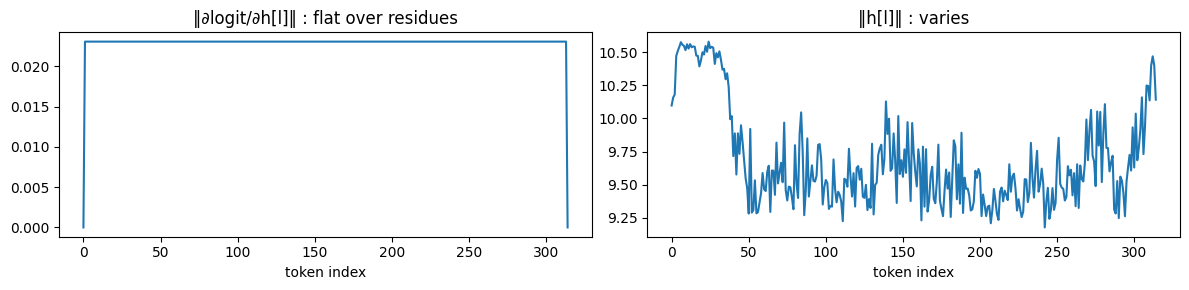

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
ax[0].plot(G.norm(dim=-1).cpu()); ax[0].set_title("‖∂logit/∂h[l]‖ : flat over residues")
ax[0].set_xlabel("token index")
ax[1].plot(h[0].detach().norm(dim=-1).cpu()); ax[1].set_title("‖h[l]‖ : varies")
ax[1].set_xlabel("token index")
plt.tight_layout(); plt.show()

## 6. Gradient × activation, an exact decomposition

$$\text{contribution}(l) = \frac{\partial\,\text{logit}}{\partial h[l]}\cdot h[l] = \frac{g\cdot h[l]}{N}$$

Summing over residues:

$$\sum_l \text{contribution}(l) = g \cdot \frac{1}{N}\sum_l h[l] = g\cdot \text{pooled}$$

So the per-residue scores **add up exactly** to `g · pooled`. That is the first-order term of the head at the pooled vector. It isn't the logit itself, because the head is non-linear.

In [11]:
contrib = (h.grad * h).sum(-1)[0].detach()            # (T,)  -- this is what the script computes
lhs = contrib.sum().item()
rhs = (g * pooled[0].detach()).sum().item()
print(f"Σ_l contribution(l) = {lhs:.6f}")
print(f"g · pooled          = {rhs:.6f}")
print(f"logit               = {logit.item():.6f}   <- differs: the head is non-linear")

# cross-check against the script's own function
c_script, _ = xr.attribution_gradcam(model, ids, mask, all_layers=False)
print("matches xr.attribution_gradcam:", torch.allclose(c_script[0, 0], contrib, atol=1e-5))

Σ_l contribution(l) = 9.823165
g · pooled          = 9.823164
logit               = 9.933744   <- differs: the head is non-linear
matches xr.attribution_gradcam: True


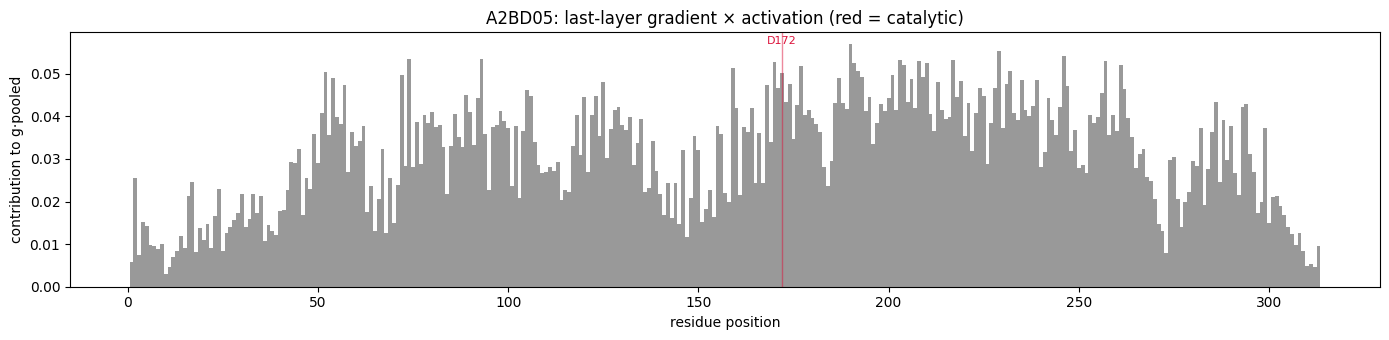

share of Σ|contribution| at catalytic residues: 0.51%  (1/313 = 0.32% of residues)


In [12]:
a_last = contrib[1:len(seq) + 1].cpu().numpy()        # drop <cls>/<eos> -> index i is residue i+1
pos = np.arange(1, len(seq) + 1)

fig, ax = plt.subplots(figsize=(14, 3.5))
ax.bar(pos, a_last, width=1.0, color="0.6")
for p in catalytic:
    ax.axvline(p, color="crimson", alpha=0.5, lw=1)
    ax.annotate(f"{seq[p-1]}{p}", (p, a_last.max()), color="crimson", fontsize=8, ha="center")
ax.set_xlabel("residue position"); ax.set_ylabel("contribution to g·pooled")
ax.set_title(f"{SEQ_ID}: last-layer gradient × activation (red = catalytic)")
plt.tight_layout(); plt.show()

cat_idx = np.array(catalytic) - 1
print(f"share of Σ|contribution| at catalytic residues: "
      f"{np.abs(a_last[cat_idx]).sum() / np.abs(a_last).sum():.2%}  "
      f"({len(catalytic)}/{len(seq)} = {len(catalytic)/len(seq):.2%} of residues)")

## 7. Every layer: a layer × position map

`output_hidden_states=True` returns 34 tensors: index 0 is the embedding output, 1–33 are the transformer blocks. The last one is `last_hidden_state` itself.

The trick is to call `retain_grad()` on **all** of them, so **one** backward pass fills every `.grad`. The cost is about 2× one inference, not 34×.

**Caveat:** below layer 33, attention mixes positions, so ∂logit/∂h_k[l] really does depend on *l*. Gradient × activation is then a first-order Taylor attribution, not an exact split. The per-layer sums below show this: only the last row adds up to `g · pooled`.

In [13]:
emb = model.backbone.get_input_embeddings()(ids).detach().requires_grad_(True)
out = model.backbone(inputs_embeds=emb, attention_mask=mask, output_hidden_states=True)
states = list(out.hidden_states)
print("number of hidden states:", len(states), "| last is last_hidden_state:", states[-1] is out.last_hidden_state)
for s in states:
    if s.requires_grad:
        s.retain_grad()
pooled = mean_pool_residues(out.last_hidden_state, mask)
logit = model.head(pooled.float()).squeeze(-1)
model.zero_grad(set_to_none=True)
logit.sum().backward()

C = torch.stack([(s.grad * s).sum(-1)[0] for s in states]).detach()   # (34, T)
A = C[:, 1:len(seq) + 1].cpu().numpy()                                # (34, L)

for k in [0, 1, 16, 32, 33]:
    print(f"layer {k:2d}: Σ_l = {A[k].sum():+.5f}")
print(f"g·pooled = {rhs:+.5f}  (only layer 33 must match)")

c_script, _ = xr.attribution_gradcam(model, ids, mask, all_layers=True)
print("matches xr.attribution_gradcam(all_layers=True):",
      np.allclose(c_script[0, :, 1:len(seq) + 1].cpu().numpy(), A, atol=1e-5))

number of hidden states: 34 | last is last_hidden_state: True
layer  0: Σ_l = -0.03372
layer  1: Σ_l = -1.88812
layer 16: Σ_l = -4.19805
layer 32: Σ_l = -4.83225
layer 33: Σ_l = +9.82316
g·pooled = +9.82316  (only layer 33 must match)
matches xr.attribution_gradcam(all_layers=True): True


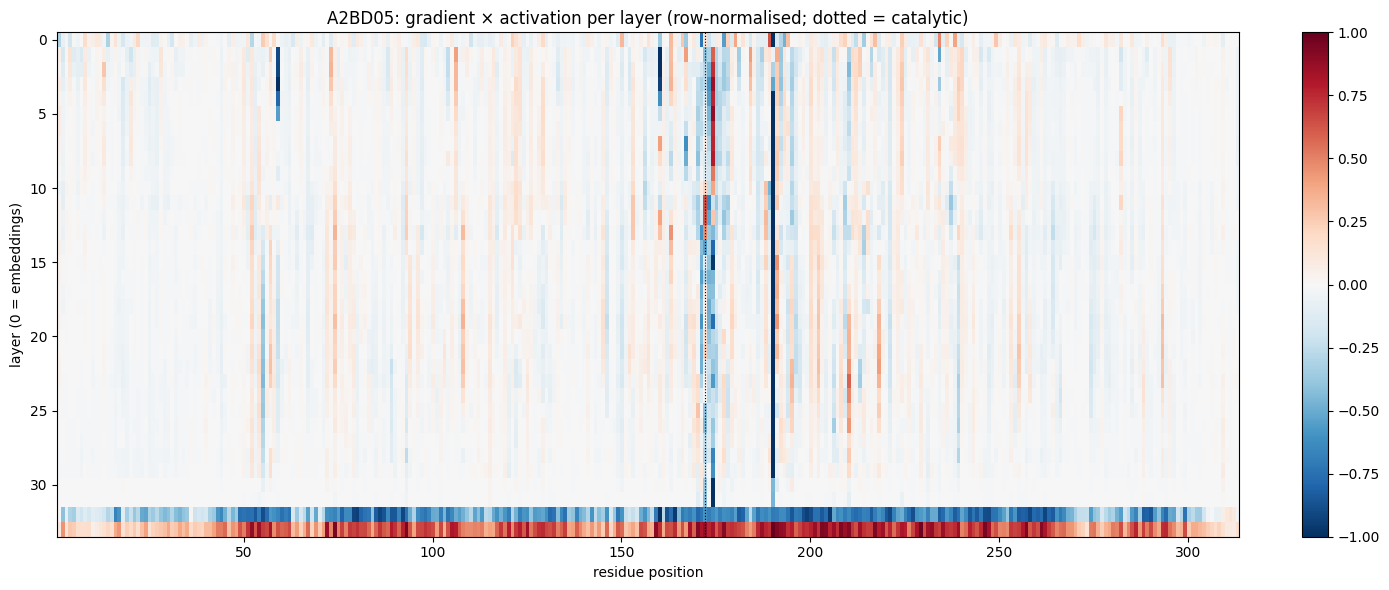

In [14]:
# rows have very different scales, so normalise each layer by its max |value| for display
An = A / np.abs(A).max(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(14, 6))
im = ax.imshow(An, aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1,
               extent=[0.5, len(seq) + 0.5, 33.5, -0.5])
for p in catalytic:
    ax.axvline(p, color="k", lw=0.8, ls=":")
ax.set_xlabel("residue position"); ax.set_ylabel("layer (0 = embeddings)")
ax.set_title(f"{SEQ_ID}: gradient × activation per layer (row-normalised; dotted = catalytic)")
plt.colorbar(im, ax=ax, fraction=0.02); plt.tight_layout(); plt.show()

Sanity check: the values recomputed here should match the precomputed CSV (both use `gradcam`, `--layers all`).

In [15]:
ref = (att[att.id == SEQ_ID].pivot(index="layer", columns="position", values="attribution")
       .sort_index().to_numpy())
print("CSV shape:", ref.shape, "| recomputed:", A.shape)
if ref.shape == A.shape:
    print("max abs diff:", np.abs(ref - A).max(), "| corr:", np.corrcoef(ref.ravel(), A.ravel())[0, 1].round(5))

CSV shape: (34, 313) | recomputed: (34, 313)
max abs diff: 8.702278137266012e-06 | corr: 1.0


## 7b. Real Grad-CAM

Grad-CAM (Selvaraju et al. 2017), carried over from CNN feature maps to transformer hidden states:

1. **Feature weights:** $\alpha^{(k)}_d = \frac{1}{N}\sum_l \frac{\partial\,\text{logit}}{\partial h_k[l,d]}$, the gradient for feature *d* (one of the 1280 hidden dimensions) averaged over residues. This is the "importance" of feature *d* at layer *k*.
2. **Map:** $\text{CAM}_k[l] = \text{ReLU}\big(\sum_d \alpha^{(k)}_d\, h_k[l,d]\big)$, each residue's features weighted by those importances. The ReLU keeps only evidence *for* "active".

The difference from gradient × activation (step 7) is that Grad-CAM uses **one averaged gradient per feature**, where gradient × activation uses the gradient at each position.

* **Layer 33:** the gradient is already the same at every position (step 5), so averaging changes nothing. Grad-CAM is **exactly** ReLU(gradient × activation).
* **Layers < 33:** the gradient varies with position, so the two maps differ.

This reuses `states` from step 7, whose `.grad` are still filled in.

In [16]:
from scipy.stats import spearmanr

cam_rows, alphas_k = [], []
for s in states:
    G_k = s.grad[0]                          # (T, 1280)  gradient at every token
    H_k = s[0].detach()                      # (T, 1280)  activations
    alpha = G_k[rmask].mean(0)               # (1280,)    feature importance: gradient averaged over real residues
    cam_rows.append(torch.relu(H_k @ alpha)) # (T,)       weighted sum of features, then ReLU
    alphas_k.append(alpha)
CAM = torch.stack(cam_rows)[:, 1:len(seq) + 1].cpu().numpy()     # (34, L)

print("layer 33: Grad-CAM == ReLU(grad × act):", np.allclose(CAM[33], np.maximum(A[33], 0), atol=1e-6))
for k in [0, 1, 16, 32, 33]:
    if not (CAM[k] > 0).any():     # ReLU removed everything: α points against every residue's features
        print(f"layer {k:2d}: Grad-CAM is 0 everywhere (no residue has positive evidence)")
        continue
    print(f"layer {k:2d}: Spearman(Grad-CAM, grad×act) = {spearmanr(CAM[k], A[k]).correlation:+.3f}"
          f"   | residues with CAM > 0: {(CAM[k] > 0).mean():.0%}")

layer 33: Grad-CAM == ReLU(grad × act): True
layer  0: Spearman(Grad-CAM, grad×act) = +0.035   | residues with CAM > 0: 55%
layer  1: Grad-CAM is 0 everywhere (no residue has positive evidence)
layer 16: Grad-CAM is 0 everywhere (no residue has positive evidence)
layer 32: Spearman(Grad-CAM, grad×act) = -0.406   | residues with CAM > 0: 55%
layer 33: Spearman(Grad-CAM, grad×act) = +1.000   | residues with CAM > 0: 100%


top-10 features at layer 33 by |α|:
  dim  550  α = -0.00244   at catalytic: -0.01   mean over residues: -0.05
  dim    1  α = -0.00235   at catalytic: -0.15   mean over residues: -0.04
  dim 1051  α = -0.00207   at catalytic: -0.05   mean over residues: -0.10
  dim 1216  α = +0.00190   at catalytic: +0.04   mean over residues: -0.12
  dim  640  α = -0.00190   at catalytic: -0.27   mean over residues: -0.02
  dim  776  α = +0.00188   at catalytic: +0.39   mean over residues: +0.11
  dim  712  α = -0.00185   at catalytic: -0.42   mean over residues: -0.01
  dim   84  α = +0.00184   at catalytic: +0.07   mean over residues: +0.12
  dim  937  α = +0.00179   at catalytic: +0.23   mean over residues: +0.17
  dim  733  α = -0.00178   at catalytic: -0.01   mean over residues: -0.19


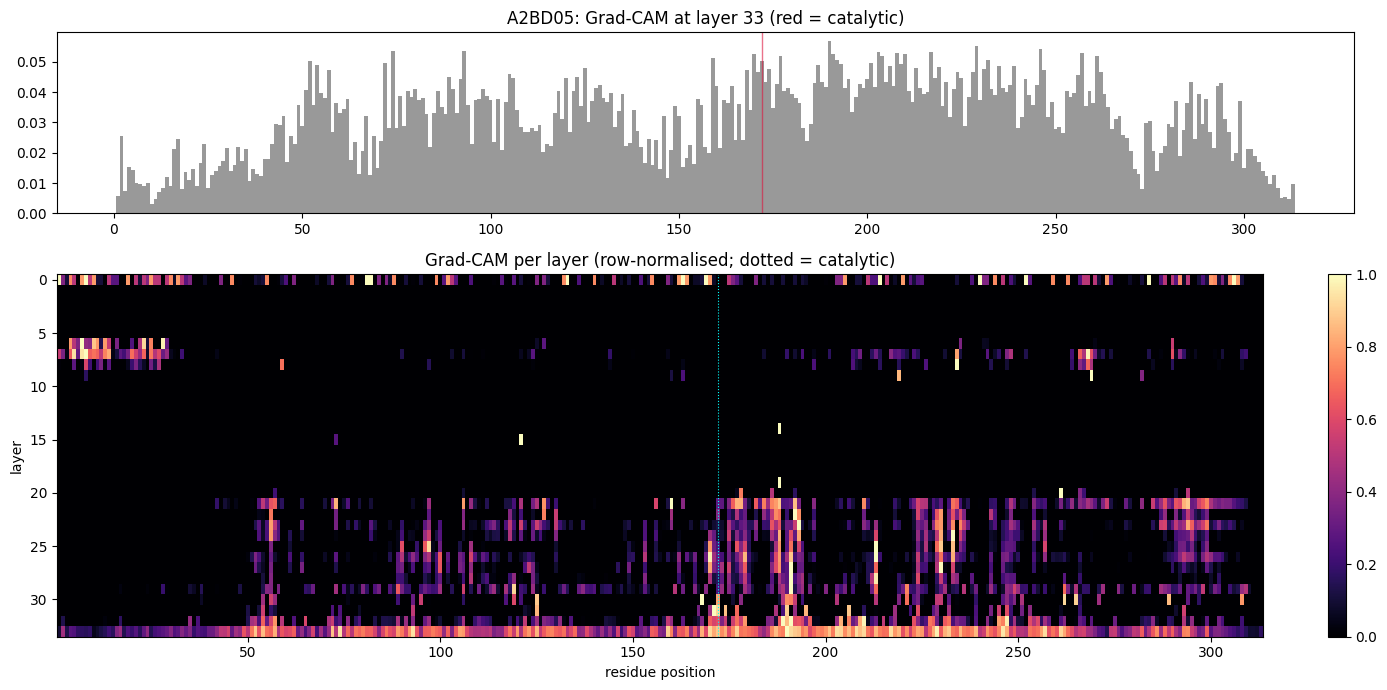

layer,0,1,2,3,4,5,6,7,8,9,...,24,25,26,27,28,29,30,31,32,33
Grad-CAM,0.23,0.50,0.50,0.50,0.50,0.50,0.46,0.35,0.43,0.49,...,0.77,0.89,0.87,0.90,0.85,0.76,0.98,1.00,0.92,0.94
grad×act,0.91,0.01,0.04,0.04,0.06,0.09,0.04,0.88,0.05,0.05,...,0.29,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.48,0.94


In [17]:
# the 1280 feature weights at the last layer: which hidden dimensions push toward "active"
alpha33 = alphas_k[-1].cpu().numpy()
top = np.argsort(-np.abs(alpha33))[:10]
print("top-10 features at layer 33 by |α|:")
for d in top:
    print(f"  dim {d:4d}  α = {alpha33[d]:+.5f}   at catalytic: "
          + ", ".join(f"{states[-1][0, p, d].item():+.2f}" for p in catalytic)
          + f"   mean over residues: {states[-1][0, rmask, d].mean().item():+.2f}")

fig, ax = plt.subplots(2, 1, figsize=(14, 7), gridspec_kw={"height_ratios": [1, 2]})
ax[0].bar(pos, CAM[33], width=1.0, color="0.6")
for p in catalytic:
    ax[0].axvline(p, color="crimson", alpha=0.6, lw=1)
ax[0].set_title(f"{SEQ_ID}: Grad-CAM at layer 33 (red = catalytic)")
CAMn = CAM / np.maximum(CAM.max(axis=1, keepdims=True), 1e-12)
im = ax[1].imshow(CAMn, aspect="auto", cmap="magma", vmin=0, vmax=1,
                  extent=[0.5, len(seq) + 0.5, 33.5, -0.5])
for p in catalytic:
    ax[1].axvline(p, color="cyan", lw=0.8, ls=":")
ax[1].set_xlabel("residue position"); ax[1].set_ylabel("layer")
ax[1].set_title("Grad-CAM per layer (row-normalised; dotted = catalytic)")
plt.colorbar(im, ax=ax[1], fraction=0.02); plt.tight_layout(); plt.show()

# percentile rank of the catalytic residue(s): Grad-CAM vs grad × act
rank = lambda M: pd.DataFrame(M.T).rank(pct=True).to_numpy().T      # rank within each layer
cmp = pd.DataFrame({"Grad-CAM": rank(CAM)[:, np.array(catalytic) - 1].mean(1),
                    "grad×act": rank(A)[:, np.array(catalytic) - 1].mean(1)})
cmp.index.name = "layer"
cmp.round(2).T

## 8. Integrated gradients (`--method intgrad`)

Gradient × activation is a linearisation, so it can miss the effect of the ReLU head and of the LoRA-adapted backbone. Integrated gradients (Sundararajan et al. 2017) integrates the gradient along a straight path from a **baseline** `x'` to the real input `x` in embedding space:

$$\text{IG}(l) = (x[l]-x'[l]) \cdot \frac{1}{S}\sum_{s=1}^{S} \frac{\partial\,\text{logit}}{\partial x[l]}\Big|_{x' + \frac{s}{S}(x-x')}$$

**Completeness axiom:** $\sum_l \text{IG}(l) \approx \text{logit}(x) - \text{logit}(x')$, and the approximation improves as `S` grows. That is the check to run.

The script uses an **all-zeros** baseline. (Its docstring says "all-`<pad>` embedding", but the code uses `torch.zeros_like`.) The cost is `S` forward and backward passes.

In [18]:
STEPS = 32 if device.type == "cuda" else 8      # CPU: keep it small

emb_layer = model.backbone.get_input_embeddings()
x = emb_layer(ids).detach()
baseline = torch.zeros_like(x)

def logit_at(inp):
    hid = model.backbone(inputs_embeds=inp, attention_mask=mask).last_hidden_state
    return model.head(mean_pool_residues(hid, mask).float()).squeeze(-1)

total = torch.zeros(x.shape[:2], device=device)
for a in torch.linspace(1.0 / STEPS, 1.0, STEPS, device=device):
    xi = (baseline + a * (x - baseline)).requires_grad_(True)
    lg = logit_at(xi)
    gi, = torch.autograd.grad(lg.sum(), xi)
    total += (gi * (x - baseline)).sum(-1)
ig = (total / STEPS)[0].detach()

with torch.no_grad():
    l_x, l_b = logit_at(x).item(), logit_at(baseline).item()
print(f"Σ IG                     = {ig.sum().item():+.4f}")
print(f"logit(x) - logit(base)   = {l_x - l_b:+.4f}   ({l_x:+.3f} - {l_b:+.3f})")
print("if these disagree, the Riemann sum missed part of the path -- see the next cell")

Σ IG                     = +58.6713
logit(x) - logit(base)   = -4.0715   (+9.934 - +14.005)
if these disagree, the Riemann sum missed part of the path -- see the next cell


### 8b. Why completeness fails here

On `A2BD05` with the zero baseline, Σ IG came out at **+58.7** (32 steps), +10.1 (128) and +60.3 (512), while the target is **−4.07**. More steps don't help, and a `<mask>`-token baseline doesn't converge either. The gradients themselves are correct: they agree with finite differences.

The plot below shows the real cause. ESM2 is a **pre-LayerNorm** transformer, and LayerNorm doesn't care about scale: `LN(a·x) = LN(x)` for any `a > 0`. So scaling the embeddings by `a` barely changes the output, except very close to `a = 0`, where the input collapses. The logit jumps within the first few percent of the path and is flat afterwards. A uniform Riemann sum either misses that jump or lands on it at random.

**Takeaway:** `--method intgrad` as implemented doesn't give trustworthy numbers for this model. Gradient × activation (steps 6–7) is the reliable method here. To keep integrated gradients, you'd need a baseline that isn't just a rescaled input, or steps concentrated near `a = 0`, plus this completeness check on every sequence.

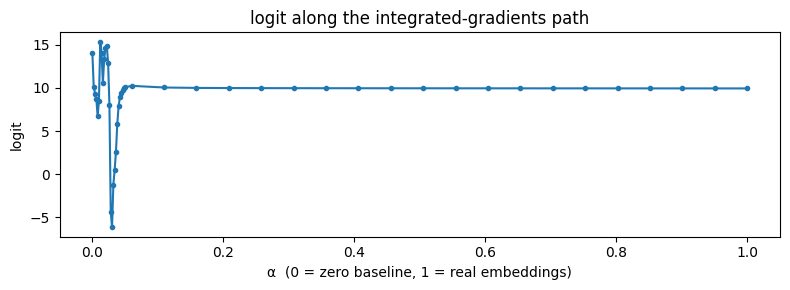

In [19]:
alphas = torch.cat([torch.linspace(0, 0.05, 26), torch.linspace(0.06, 1, 20)]).to(device)
with torch.no_grad():
    path = [logit_at(baseline + a * (x - baseline)).item() for a in alphas]
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(alphas.cpu(), path, ".-")
ax.set_xlabel("α  (0 = zero baseline, 1 = real embeddings)"); ax.set_ylabel("logit")
ax.set_title("logit along the integrated-gradients path")
plt.tight_layout(); plt.show()

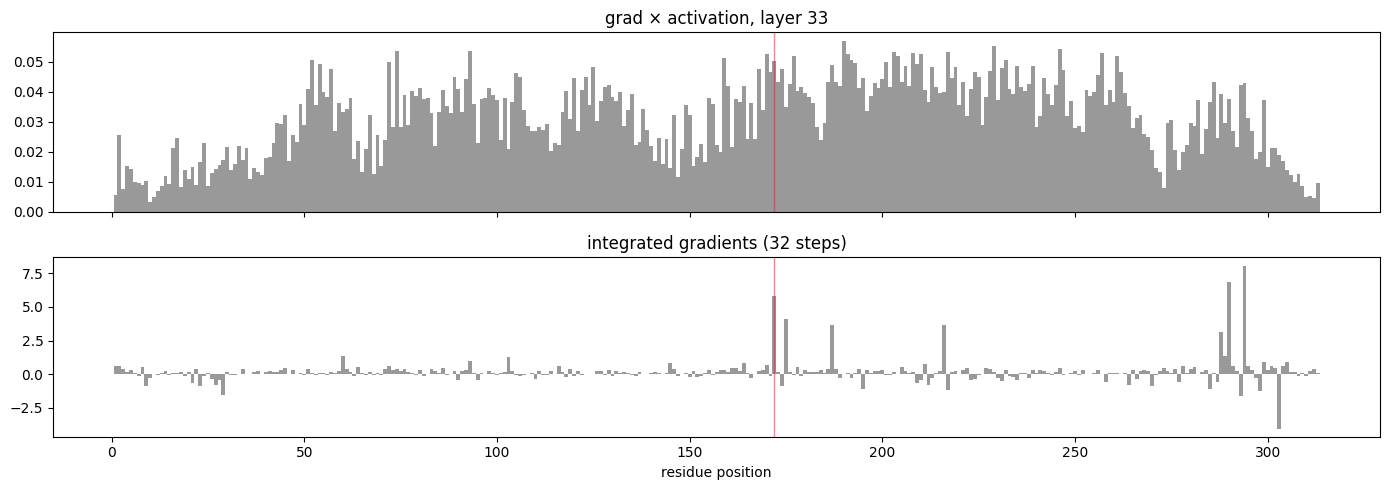

Spearman(grad×act last layer, IG): 0.026


In [20]:
ig_res = ig[1:len(seq) + 1].cpu().numpy()
fig, ax = plt.subplots(2, 1, figsize=(14, 5), sharex=True)
for a_, title, axi in [(a_last, "grad × activation, layer 33", ax[0]), (ig_res, f"integrated gradients ({STEPS} steps)", ax[1])]:
    axi.bar(pos, a_, width=1.0, color="0.6")
    for p in catalytic:
        axi.axvline(p, color="crimson", alpha=0.5, lw=1)
    axi.set_title(title)
ax[1].set_xlabel("residue position"); plt.tight_layout(); plt.show()

from scipy.stats import spearmanr
print("Spearman(grad×act last layer, IG):", round(spearmanr(a_last, ig_res).correlation, 3))

## 9. Does the model look at the catalytic residues? (the score)

Raw attributions can't be compared across sequences, because length and scale differ. So the script converts them to a **percentile rank within each (sequence, layer)**:

* `mean_pct_rank_catalytic`: 0.5 is chance.
* `catalytic_in_top10pct`: the fraction of catalytic residues in the top 10% most-attributed. 0.10 is chance.
* `enrichment_top10pct` = that fraction / 0.10. **1.0 is chance, and this is the headline number.**

Here it is for the single sequence (noisy, since there are only a handful of catalytic residues):

In [21]:
one = pd.DataFrame({"layer": np.repeat(np.arange(A.shape[0]), len(seq)),
                    "position": np.tile(pos, A.shape[0]),
                    "attribution": A.ravel()})
one["is_catalytic"] = one.position.isin(catalytic)
one["pct_rank"] = one.groupby("layer").attribution.rank(pct=True)

cat_rank = one[one.is_catalytic].pivot(index="layer", columns="position", values="pct_rank")
cat_rank.columns = [f"{seq[p-1]}{p}" for p in cat_rank.columns]
cat_rank.round(2).T

layer,0,1,2,3,4,5,6,7,8,9,...,24,25,26,27,28,29,30,31,32,33
D172,0.91,0.01,0.04,0.04,0.06,0.09,0.04,0.88,0.05,0.05,...,0.29,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.48,0.94


Note that the rank uses the **signed** attribution. A residue that pushes strongly *against* "active" ranks near 0, not near 1. So the metric asks "which residues push toward *active*?", not "which residues matter?".

## 10. All 200 sequences (reproducing `summary.json`)

This is the summary block of `main()` applied to the precomputed `attributions.csv`. It doesn't need the model.

In [22]:
df = att.copy()
df["pct_rank"] = df.groupby(["id", "layer"]).attribution.rank(pct=True)

per_layer = []
for layer, sub in df.groupby("layer"):
    c = sub[sub.is_catalytic]
    top = float((c.pct_rank >= 0.90).mean())
    per_layer.append({"layer": int(layer),
                      "mean_pct_rank_catalytic": c.pct_rank.mean(),
                      "mean_pct_rank_background": sub[~sub.is_catalytic].pct_rank.mean(),
                      "catalytic_in_top10pct": top,
                      "enrichment_top10pct": top / 0.10})
per_layer = pd.DataFrame(per_layer).set_index("layer")

saved = pd.DataFrame(json.load(open(os.path.join(XAI_DIR, "summary.json")))["per_layer"]).set_index("layer")
print("matches summary.json:", np.allclose(per_layer.enrichment_top10pct.round(3), saved.enrichment_top10pct, atol=1e-3))
per_layer.round(3)

matches summary.json: True


,mean_pct_rank_catalytic,mean_pct_rank_background,catalytic_in_top10pct,enrichment_top10pct
layer,,,,
0,0.640,0.501,0.530,5.304
1,0.485,0.501,0.390,3.898
2,0.507,0.501,0.409,4.089
3,0.505,0.501,0.412,4.121
4,0.502,0.501,0.409,4.089
5,0.506,0.501,0.422,4.217
6,0.498,0.501,0.412,4.121
7,0.503,0.501,0.415,4.153
8,0.472,0.501,0.403,4.026


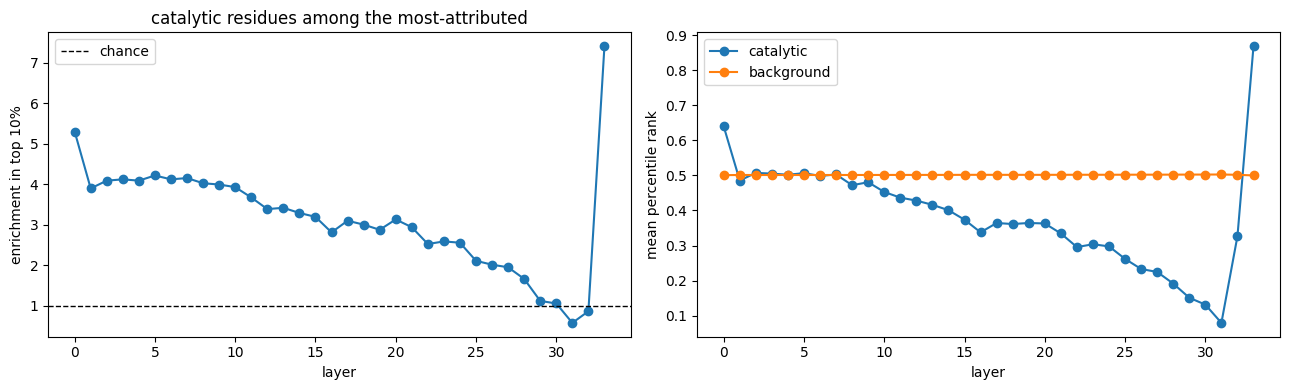

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(per_layer.index, per_layer.enrichment_top10pct, "o-")
ax[0].axhline(1, color="k", ls="--", lw=1, label="chance")
ax[0].set_xlabel("layer"); ax[0].set_ylabel("enrichment in top 10%"); ax[0].legend()
ax[0].set_title("catalytic residues among the most-attributed")
ax[1].plot(per_layer.index, per_layer.mean_pct_rank_catalytic, "o-", label="catalytic")
ax[1].plot(per_layer.index, per_layer.mean_pct_rank_background, "o-", label="background")
ax[1].set_xlabel("layer"); ax[1].set_ylabel("mean percentile rank"); ax[1].legend()
plt.tight_layout(); plt.show()

### 10b. The amino-acid confound

Catalytic residues are mostly His, Cys and Asp, which are rare in the background. A model that just up-weights those **letters** would score a high enrichment without locating any site. The fair comparison is **within each residue type**: catalytic His vs non-catalytic His, and so on. `plot_xai.py` panel (e) runs this test. Here it is at the last layer:

In [24]:
last = df[df.layer == df.layer.max()]
by_aa = (last.groupby(["residue", "is_catalytic"]).pct_rank.mean().unstack()
         .rename(columns={False: "non-catalytic", True: "catalytic"}))
by_aa["n_catalytic"] = last[last.is_catalytic].groupby("residue").size()
by_aa = by_aa.dropna().sort_values("n_catalytic", ascending=False)
by_aa.round(3)

is_catalytic,non-catalytic,catalytic,n_catalytic
residue,,,
H,0.482,0.888,82.0
D,0.514,0.880,76.0
C,0.537,0.931,38.0
E,0.494,0.851,38.0
K,0.414,0.802,24.0
Y,0.495,0.784,20.0
S,0.454,0.820,20.0
T,0.452,0.976,6.0
R,0.439,0.737,5.0


**How to read this:** if catalytic ≫ non-catalytic **within** the same amino acid, the model is picking out *the* site, not just the residue type. If the two columns are about equal, the enrichment in the plot above comes from residue identity.

---
**Next:** change `SEQ_ID` in step 2 to explore other sequences, or point `RUN_DIR` / `XAI_DIR` at `lora_r8_posw` to compare runs.

## 11. The sequence, coloured by importance

Each amino acid is drawn as a letter on a tile whose colour shows its attribution. Catalytic residues have a **black outline**. Change `SCORE` to view another map:

* `A[33]`: gradient × activation at the last layer. Signed: red pushes toward *active*, blue pushes away.
* `CAM[33]`: Grad-CAM at the last layer, which is the same map with the negatives set to 0.
* `A[k]` / `CAM[k]`: any other layer *k*.
* `ig_res`: integrated gradients (see step 8b before trusting it).

Colours are scaled to the 99th percentile of |score|, so one extreme residue doesn't wash out the rest.

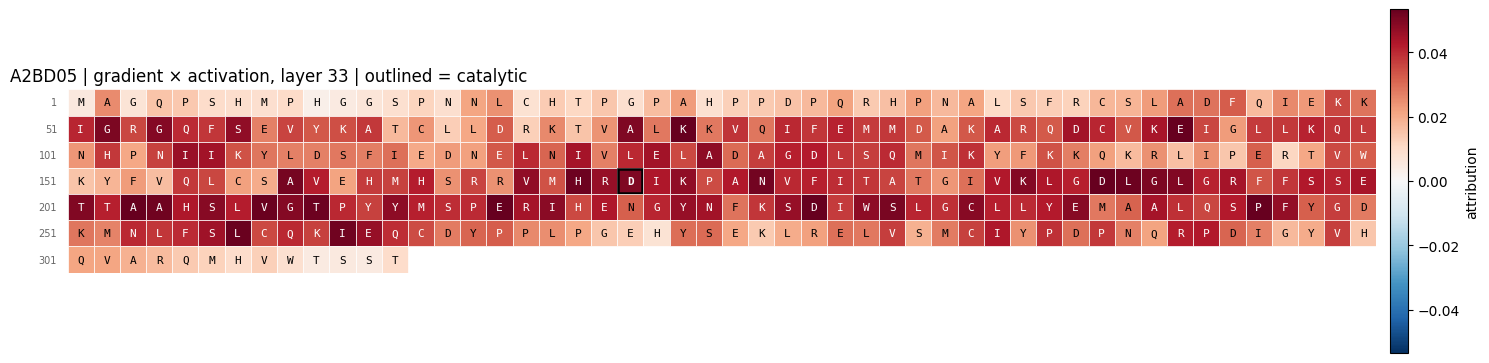

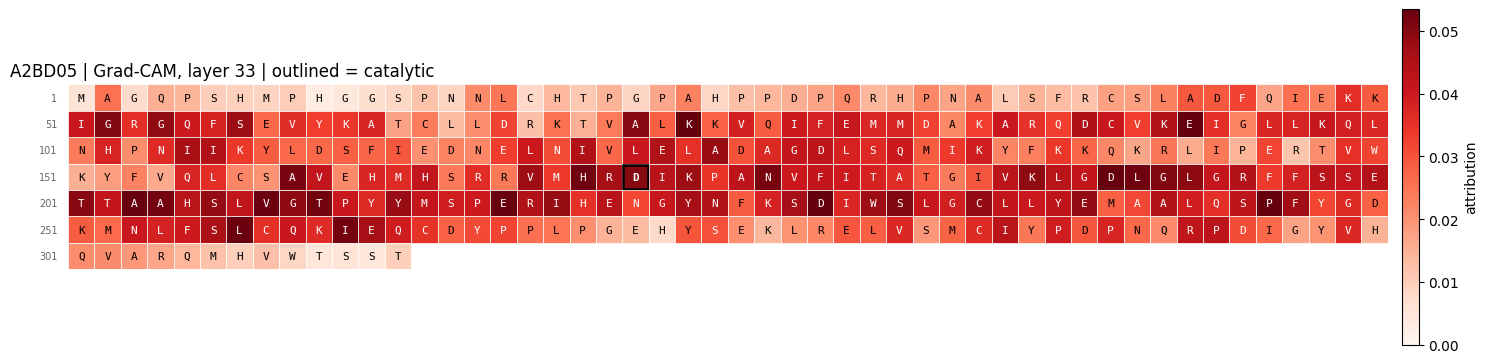

top-10 residues: D190, D229, P246, E93, K74, A203, E217, V208, L257, H170   (* = catalytic)


In [25]:
from matplotlib.patches import Rectangle
from matplotlib.colors import TwoSlopeNorm, Normalize

def plot_sequence_importance(seq, scores, catalytic=(), title="", per_row=50, signed=True):
    scores = np.asarray(scores, dtype=float)
    lim = np.percentile(np.abs(scores), 99) or 1.0
    if signed:
        cmap, norm = plt.cm.RdBu_r, TwoSlopeNorm(vcenter=0, vmin=-lim, vmax=lim)
    else:
        cmap, norm = plt.cm.Reds, Normalize(vmin=0, vmax=lim)
    n_rows = int(np.ceil(len(seq) / per_row))
    fig, ax = plt.subplots(figsize=(per_row * 0.27 + 1.5, n_rows * 0.42 + 0.8))
    cat = set(catalytic)
    for i, (aa, v) in enumerate(zip(seq, scores)):
        r, c = divmod(i, per_row)
        y = n_rows - 1 - r
        rgba = cmap(norm(np.clip(v, -lim, lim)))
        ax.add_patch(Rectangle((c, y), 1, 1, facecolor=rgba, edgecolor="white", lw=0.5))
        dark = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2] < 0.5
        ax.text(c + 0.5, y + 0.5, aa, ha="center", va="center", fontsize=8, family="monospace",
                color="white" if dark else "black", fontweight="bold" if i + 1 in cat else "normal")
        if i + 1 in cat:
            ax.add_patch(Rectangle((c + 0.04, y + 0.04), 0.92, 0.92, fill=False, edgecolor="black", lw=1.8))
    for r in range(n_rows):                       # residue number at the start of each row
        ax.text(-0.4, n_rows - 1 - r + 0.5, str(r * per_row + 1), ha="right", va="center", fontsize=7, color="0.4")
    ax.set_xlim(-2.2, per_row); ax.set_ylim(0, n_rows)
    ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(title, loc="left")
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    fig.colorbar(sm, ax=ax, fraction=0.015, pad=0.01, label="attribution")
    plt.tight_layout(); plt.show()

SCORE, NAME = A[33], "gradient × activation, layer 33"
plot_sequence_importance(seq, SCORE, catalytic, title=f"{SEQ_ID} | {NAME} | outlined = catalytic")
plot_sequence_importance(seq, CAM[33], catalytic, signed=False,
                         title=f"{SEQ_ID} | Grad-CAM, layer 33 | outlined = catalytic")

top = np.argsort(-SCORE)[:10] + 1
print("top-10 residues:", ", ".join(f"{seq[p-1]}{p}{'*' if p in catalytic else ''}" for p in top), "  (* = catalytic)")